In [1]:
import numpy as np
import pandas as pd
import itertools
from mass_function import MassFunction


In [2]:
# 説明の数値a
ALPHA = 0.1


# データ取得

df_data は各物質の構成元素=1，非構成元素=0 を含むデータです．

In [3]:
ROOT = ".."
df_data = pd.read_csv(f"{ROOT}/data/HEA_data.demo.csv", index_col=0)
ELEMENTS = np.array([
    "Ti", "V", "Cr", "Mn", "Fe", "Co", "Ni", "Cu",
    "Zr", "Nb", "Mo", "Tc", "Ru", "Rh", "Pd", "Ag"])


## 例

- 元素２つから成る物質AgFe観測データを探す。存在するかはlabel_alloy_iで与えられる。
- 元素２つから成る物質CuFe観測データを探す。存在するかはlabel_alloy_jで与えられる。

Feが共通元素でAg->Cuという置換。

In [4]:
from ERS_misc import extract_evidence
alloy_i = ["Ag", "Fe"]
query_string = "Ag==1 and Fe==1 and n_element==2"
label_alloy_i = df_data.query(query_string).iloc[0]["Label"]
alloy_j = ["Cu", "Fe"]
query_string = "Cu==1 and Fe==1 and n_element==2"
label_alloy_j = df_data.query(query_string).iloc[0]["Label"]
evidence_1 = extract_evidence(frozenset(alloy_i), frozenset(alloy_j))
print("evidence:", evidence_1, label_alloy_i, label_alloy_j)
if evidence_1 is not None: # 共通元素を持たなければNone
    combination_t, combination_v = evidence_1
    if label_alloy_i == label_alloy_j: # （有、有）もしくは（無、無）のペア。
        mass_function_1 = MassFunction(source=[({"similar"}, 
                                               ALPHA)],
                                       coreset={"similar", "dissimilar"})
    else: # （有、無）もしくは（無、有）のペア。
        mass_function_1 = MassFunction(source=[({"dissimilar"}, 
                                                ALPHA)],
                                       coreset={"similar", "dissimilar"})
    print(mass_function_1)


evidence: (frozenset({'Ag'}), frozenset({'Cu'})) not_HEA not_HEA
{frozenset({'similar'}): 0.1, frozenset({'dissimilar'}): 0, frozenset({'dissimilar', 'similar'}): 0.9}


- 元素３つから成る物質AgPdV観測データを探す。存在するかはlabel_alloy_iで与えられる。
- 元素３つから成る物質CuPdV観測データを探す。存在するかはlabel_alloy_jで与えられる。

PdVが共通元素でAg->Cuという置換。

In [5]:
alloy_i = ["Ag", "Pd", "V"]
query_string = "Ag==1 and Pd==1 and V==1 and n_element==3"
label_alloy_i = df_data.query(query_string).iloc[0]["Label"]
alloy_j = ["Cu", "Pd", "V"]
query_string = "Cu==1 and Pd==1 and V==1 and n_element==3"
label_alloy_j = df_data.query(query_string).iloc[0]["Label"]
evidence_2 = extract_evidence(frozenset(alloy_i), frozenset(alloy_j))
print("evidence:", evidence_1, label_alloy_i, label_alloy_j)
if evidence_2 is not None:# 共通元素を持たなければNone
    combination_v, similar = evidence_2
    if label_alloy_i == label_alloy_j:
        mass_function_2 = MassFunction(source=[({"similar"}, 
                                                ALPHA)],
                                       coreset={"similar", "dissimilar"})
    else:
        mass_function_2 = MassFunction(source=[({"dissimilar"}, 
                                               ALPHA)],
                                       coreset={"similar", "dissimilar"})
    print(mass_function_2)


evidence: (frozenset({'Ag'}), frozenset({'Cu'})) not_HEA HEA
{frozenset({'dissimilar'}): 0.1, frozenset({'similar'}): 0, frozenset({'dissimilar', 'similar'}): 0.9}


In [6]:
combined_mass_function = mass_function_1.combine(mass_function_2) #結合
print(combined_mass_function)


{frozenset({'dissimilar'}): 0.09090909090909091, frozenset({'similar'}): 0.09090909090909091, frozenset({'dissimilar', 'similar'}): 0.8181818181818181}


# 第一段階

全ての組み合わせに対して適用して、原子間の信念割当関数を求める。

In [7]:
import progressbar
nall = int(df_data.shape[0]*(df_data.shape[0]-1)/2)
bar = progressbar.ProgressBar(max_value=nall)
iteration = itertools.combinations(df_data.index.values, 2)
mass_functions = []
for i, (index_alloy_i, index_alloy_j) in enumerate(iteration):
    bar.update(i+1)
    df_alloy_i = df_data.loc[index_alloy_i]
    df_alloy_j = df_data.loc[index_alloy_j]
    alloy_i = ELEMENTS[df_alloy_i[ELEMENTS].values == 1].tolist()
    label_alloy_i = df_alloy_i["Label"]
    alloy_j = ELEMENTS[df_alloy_j[ELEMENTS].values == 1].tolist()
    label_alloy_j = df_alloy_j["Label"]
    evidence = extract_evidence(frozenset(alloy_i), frozenset(alloy_j))
    if evidence is not None:
        combination_t, combination_v = evidence
        if label_alloy_i == label_alloy_j:
            mass_function = MassFunction(source=[({"similar"},
                                                 ALPHA)],
                                         coreset={"similar", "dissimilar"})
        else:
            mass_function = MassFunction(source=[({"dissimilar"},
                                                  ALPHA)],
                                         coreset={"similar", "dissimilar"})
        mass_functions.append([combination_t, combination_v, mass_function])


  0% (0 of 72390) |                      | Elapsed Time: 0:00:00 ETA:  --:--:--

  0% (511 of 72390) |                    | Elapsed Time: 0:00:00 ETA:   0:00:43

  1% (1006 of 72390) |                   | Elapsed Time: 0:00:00 ETA:   0:00:34

  2% (1495 of 72390) |                   | Elapsed Time: 0:00:00 ETA:   0:00:29

  2% (2056 of 72390) |                   | Elapsed Time: 0:00:00 ETA:   0:00:26

  3% (2620 of 72390) |                   | Elapsed Time: 0:00:00 ETA:   0:00:25

... (150 outputs left out)

 97% (70695 of 72390) |################# | Elapsed Time: 0:00:21 ETA:   0:00:00

 98% (71163 of 72390) |################# | Elapsed Time: 0:00:22 ETA:   0:00:00

 98% (71613 of 72390) |################# | Elapsed Time: 0:00:22 ETA:   0:00:00

 99% (72105 of 72390) |################# | Elapsed Time: 0:00:22 ETA:   0:00:00

証拠を統合し、
信念構造,m{類似}、m({非類似})、m({類似,非類似})を別々のデータフレームとして取り出す。

In [8]:
from ERS_misc import make_similarity_df
df_similarity, df_dissimilarity, df_unknown = make_similarity_df(ELEMENTS,
                                                           mass_functions)

['', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Ti|V', 'Cr|Ti', 'Mn|Ti', 'Fe|Ti', 'Co|Ti', 'Ni|Ti', 'Cu|Ti', 'Ti|Zr', 'Nb|Ti', 'Mo|Ti', 'Tc|Ti', 'Ru|Ti', 'Rh|Ti', 'Pd|Ti', 'Ag|Ti', 'Cr|V', 'Mn|V', 'Fe|V', 'Co|V', 'Ni|V', 'Cu|V', 'V|Zr', 'Nb|V', 'Mo|V', 'Tc|V', 'Ru|V', 'Rh|V', 'Pd|V', 'Ag|V', 'Cr|Mn', 'Cr|Fe', 'Co|Cr', 'Cr|Ni', 'Cr|Cu', 'Cr|Zr', 'Cr|Nb', 'Cr|Mo', 'Cr|Tc', 'Cr|Ru', 'Cr|Rh', 'Cr|Pd', 'Ag|Cr', 'Fe|Mn', 'Co|Mn', 'Mn|Ni', 'Cu|Mn', 'Mn|Zr', 'Mn|Nb', 'Mn|Mo', 'Mn|Tc', 'Mn|Ru', 'Mn|Rh', 'Mn|Pd', 'Ag|Mn', 'Co|Fe', 'Fe|Ni', 'Cu|Fe', 'Fe|Zr', 'Fe|Nb', 'Fe|Mo', 'Fe|Tc', 'Fe|Ru', 'Fe|Rh', 'Fe|Pd', 'Ag|Fe', 'Co|Ni', 'Co|Cu', 'Co|Zr', 'Co|Nb', 'Co|Mo', 'Co|Tc', 'Co|Ru', 'Co|Rh', 'Co|Pd', 'Ag|Co', 'Cu|Ni', 'Ni|Zr', 'Nb|Ni', 'Mo|Ni', 'Ni|Tc', 'Ni|Ru', 'Ni|Rh', 'Ni|Pd', 'Ag|Ni', 'Cu|Zr', 'Cu|Nb', 'Cu|Mo', 'Cu|Tc', 'Cu|Ru', 'Cu|Rh', 'Cu|Pd', 'Ag|Cu', 'Nb|Zr', 'Mo|Zr', 'Tc|Zr', 'Ru|Zr', 'Rh|Zr', 'Pd|Zr', 'Ag|Zr', 'Mo|Nb', 'Nb|Tc', 'Nb|Ru

Cr Nb|Ti
Cr Ti|V
 Co|Ni
 Fe|Mo
 Fe|V
 Mo|Nb
 Nb|V
 Co|Mo
 Fe|Nb
 Mo|Ni
 Mo|Ti
 Mo|Zr
 Ni|V
 Ti|Zr
 Co|Nb
 Cu|Fe
 Cu|V
 Fe|Ni
 Fe|Ti
 Mo|V
 Nb|Ni
 Nb|Ti
 Nb|Zr
 Ti|V
Nb V
Cr Fe
Cr Mn
Cr Mo
Cr V
Cr Zr
Nb Co
Nb Cu
Nb Mo
Nb Ni
Nb Rh
Nb Ti
Cr Ti
Nb Co|Cu
Nb Co|Mn
Nb Co|Ni
Nb Cu|Fe
Nb Cu|Ni
Nb Cu|V
Nb Fe|Mo
Nb Fe|Ni
Nb Fe|V
 Mn
Nb Mn|Rh
Nb Mn|Ti
Nb Mo|Tc
Nb Mo|V
Nb Mo|Zr
 Ti
Nb Ni|Pd
Nb Ni|Rh
Nb Pd|Rh
Cr Fe|Mn
Cr Fe|Mo
Cr Fe|V
Cr Mn|V
Cr Mo|Tc
Cr Mo|V
Cr Mo|Zr
Cr Pd|Rh
 Co
Nb Co|Pd
Nb Co|Rh
Nb Cu|Mo
Nb Cu|Pd
Nb Cu|Rh
Nb Fe|Mn
 Fe
Nb Fe|Rh
Nb Fe|Ti
Nb Mn|Mo
Nb Mn|Ni
Nb Mn|V
 Mo
Nb Mo|Ti
 V
 Zr
Nb Ti|V
Nb Ti|Zr
Cr Fe|Ti
Cr Mn|Mo
Cr Mn|Ti
Cr Mo|Ti
Cr Tc|V
Cr Ti|V
Cr Ti|Zr
Cr V|Zr
 Cu|Ti
 Fe|V
 Mn|Mo
 Mn|V
 Ni|V
 Ti|Zr
 Co|Mo
 Cu|Fe
 Cu|V
 Fe|Mn
 Mo|Ni
 Mo|Ti
 Mo|Zr
 Ti|V
 Co|Mn
 Fe|Mo
 Fe|Ti
 Mn|Ni
 Mn|Ti
 Mn|Zr
 Mo|V
 V|Zr
Cr Nb
Cr Rh
V Co
V Cu
V Mo
V Ni
V Rh
V Ti
Cr Cu
Cr Mn
Cr Mo
Cr Ni
Cr Ti
Cr Zr
Cr Ag|Ti
V Co|Cu
V Co|Mn
V Co|Ni
Cr Co|Pd
Cr Co|Rh
V Cu|Fe
V Cu|Ni
 Cu
V Fe|Mo
V Fe|Ni
 Fe
V Mn

Ru Nb|Zr
Ru Tc|V
Ru Ti|V
Ru Ti|Zr
Ru V|Zr
Ru Co|Ni
Ru Co|Rh
Ru Cr|Cu
Ru Cr|Mn
Ru Cr|Nb
Ru Cr|Ti
Ru Fe|Mn
Ru Fe|Ni
Ru Fe|Rh
Ru Fe|Ti
Ru Mn|Nb
Ru Mn|Ti
Ru Nb|Ti
Ru Ni|Pd
Ru Ni|Rh
Ru Pd|Rh
Ru Tc|Ti
 Ag|Fe
 Ag|Pd
 Co|Pd
 Ag|Co
 Fe|Pd
 Pd|Rh
 Ag|Ni
 Ag|Rh
 Ni|Pd
Mo Ag
Ti Co
Ti Cr
Mo Cr
Ti Fe
Ti Ni
Ti Rh
Ti V
Ti Zr
Mo Nb
Mo V
Mo Zr
Mo Ag|Cu
Mo Ag|V
Ti Cr|Fe
Mo Cr|Mn
Ti Cr|Tc
Ti Cr|V
Ti Cr|Zr
Mo Cr|Nb
Mo Cu|Pd
Mo Cu|Zr
Mo Fe|Mn
Ti Fe|Nb
Ti Fe|Pd
Ti Fe|V
Ti Mn|V
Ti Nb|Tc
Ti Nb|V
Ti Nb|Zr
Ti Tc|V
 V
 Zr
Ti V|Zr
Mo V|Zr
Mo Ag|Zr
Ti Co|Ni
Ti Co|Rh
Ti Cr|Cu
Mo Cr|Fe
Ti Cr|Mn
Ti Cr|Nb
 Cr
Mo Cr|V
Mo Cr|Zr
Mo Cu|V
Ti Fe|Mn
Ti Fe|Ni
Ti Fe|Rh
 Fe
Mo Fe|Nb
Mo Fe|V
Ti Mn|Nb
 Mn
Mo Mn|Nb
Mo Mn|V
 Nb
Ti Ni|Pd
Ti Ni|Rh
Ti Pd|Rh
 Tc
Mo Nb|V
Mo Nb|Zr
Mo Pd|V
 Cr|Fe
 Cr|V
 Fe|Mn
 Fe|V
 Mn|V
 Nb|V
 Cr|Mn
 Cr|Nb
 Cu|Fe
 Cu|V
 Mn|Nb
 V|Zr
 Cr|Cu
 Cr|Zr
 Fe|Nb
 Mn|Zr
 Nb|Zr
V Zr
Nb Rh
Nb Cu
Nb Mn
Nb Mo
V Ti
Nb Ni
Nb Ti
Nb Zr
Nb Ag|Ti
Nb Co|Pd
Nb Co|Rh
Nb Cr|Cu
Nb Cr|Fe
V Cr|Mn
Nb Cr|Mo
V Cr|Ti
Nb Cu|Fe
Nb Cu|Rh
V

Cu Ni
Cu Rh
Cu Ti
Cr Pd
Cr Rh
Cr V
Cr Ag|Co
Cr Ag|Fe
Cr Ag|Mn
Cr Ag|Pd
Cr Ag|Rh
Cr Ag|Ti
Cr Ag|Zr
 Co
Cu Co|Mn
Cu Co|Ni
Cr Co|Mn
Cr Co|Pd
Cr Co|Rh
 Fe
 Ni
 V
Cu Fe|Mo
Cu Fe|Ni
Cu Fe|V
Cu Mn|Nb
Cu Mn|Rh
Cu Mn|Ti
Cu Mo|Tc
Cu Mo|V
Cu Mo|Zr
Cu Nb|Ti
Cu Ni|Pd
Cu Ni|Rh
Cu Pd|Rh
Cr Fe|Mn
Cr Fe|Pd
Cr Fe|V
Cr Mn|Ni
Cr Pd|Ti
Cr Rh|V
Cr Ti|Zr
Cr Ag|Ni
Cr Ag|V
Cu Co|Nb
Cu Co|Pd
Cu Co|Rh
Cr Co|Ni
Cr Co|V
 Mo
 Pd
 Rh
Cu Fe|Mn
Cu Fe|Nb
Cu Fe|Rh
Cu Fe|Ti
Cu Mn|Mo
Cu Mn|Ni
Cu Mn|V
Cu Mo|Nb
Cu Mo|Ti
Cu Nb|V
Cu Nb|Zr
Cu Ti|V
Cu Ti|Zr
Cr Fe|Ni
Cr Fe|Rh
Cr Ni|Pd
Cr Ni|Rh
Cr Ni|V
Cr Pd|Rh
Cr Pd|V
Cr Ti|V
 Ag|Co
 Ag|Pd
 Ag|Ru
 Fe|Mo
 Fe|Pd
 Mo|V
 Nb|Ti
 Ni|Pd
 Pd|Ru
 Ti|V
 Ag|Fe
 Co|Ni
 Fe|Nb
 Fe|V
 Nb|V
 Ag|Ni
 Ag|Rh
 Co|Pd
 Fe|Mn
 Fe|Ni
 Mn|V
 Mo|Ti
 Pd|Rh
Mo Ni
Mo Rh
Mo Ti
Cr Fe
Cr Ni
Cr Rh
Cr V
Cr Zr
Mo Co|Cu
Mo Co|Mn
Mo Co|Ni
Mo Cu|Fe
Mo Cu|Ni
Mo Cu|V
 Fe
Mo Fe|Ni
Mo Fe|V
Mo Mn|Nb
Mo Mn|Rh
Mo Mn|Ti
 Tc
 V
 Zr
Mo Nb|Ti
Mo Ni|Pd
Mo Ni|Rh
Mo Pd|Rh
Cr Fe|Nb
Cr Fe|Pd
Cr Fe|V
Cr Mn|V
Cr Nb|Tc
Cr Nb|V
Cr Nb|Zr

Mn Pd|Rh
Mn Ti|Zr
Mn Ag|Cu
Mn Ag|Pd
Mn Co|Cu
V Co|Ni
Mn Co|Ni
V Cr|Fe
V Cr|Mo
V Cr|Ni
 Cr
Mn Cr|Nb
Mn Cr|Ti
Mn Cu|Ni
Mn Cu|Pd
Mn Cu|Ti
V Fe|Mo
V Fe|Ni
 Fe
Mn Fe|Ti
V Mo|Nb
V Mo|Ti
V Nb|Ti
 Ti
Mn Nb|Tc
Mn Nb|Ti
Mn Nb|Zr
Mn Ni|Pd
Mn Ni|Rh
Mn Pd|Ti
 Cr|Fe
 Cr|Nb
 Cu|Fe
 Cu|Mo
 Cu|Nb
 Cu|Ti
 Fe|Nb
 Fe|Ti
 Mo|Ti
 Nb|Ni
 Cr|Ni
 Fe|Mo
 Mo|Zr
 Nb|Ti
 Cr|Cu
 Cr|Mo
 Cr|Ti
 Mo|Nb
 Mo|Ni
 Nb|Zr
 Ti|Zr
Ni Rh
Ni V
Ni Zr
Mo Pd
Mo Rh
Mo V
Mo Ag|Pd
Mo Ag|Rh
Mo Co|Cr
Mo Co|Pd
Mo Co|Rh
Mo Cr|Cu
Ni Cr|Fe
Mo Cr|Fe
Ni Cr|Tc
Ni Cr|V
Ni Cr|Zr
Mo Cr|Pd
Mo Cr|Rh
Mo Cu|Mn
Ni Fe|Nb
Ni Fe|Pd
Ni Fe|V
Ni Mn|V
Ni Nb|Tc
Ni Nb|V
Ni Nb|Zr
Ni Tc|V
Ni Ti|V
Ni Ti|Zr
Ni V|Zr
Mo Pd|Rh
Mo Ag|Cu
Mo Ag|Fe
Mo Co|Cu
Mo Co|Mn
 Co
Ni Co|Rh
Mo Co|V
Ni Cr|Cu
Ni Cr|Mn
Mo Cr|Mn
Ni Cr|Nb
Ni Cr|Ti
Mo Cu|Fe
Mo Cu|Pd
Mo Cu|Rh
Mo Cu|V
Ni Fe|Mn
Mo Fe|Mn
 Fe
Ni Fe|Rh
Ni Fe|Ti
Mo Fe|Rh
Ni Mn|Nb
Ni Mn|Ti
Ni Nb|Ti
 Pd
 Rh
Ni Pd|Rh
Ni Tc|Ti
Mo Pd|V
Mo Rh|V
 Cr|Fe
 Fe|V
 Ag|Co
 Ag|Fe
 Ag|Pd
 Ag|Rh
 Cr|Mn
 Cr|Nb
 Pd|Rh
 Ag|Ru
 Co|Pd
 Fe|Pd
 Mn|V
 N

Ag|Cu Cr|Mn
Ag|Cu Cr|Ni
Ag Mn
Ag Pd
Ag Rh
Ag|Cu Mn|Rh
Ag|Cu Ni|Pd
Ag|Cu Ni|Rh
Ag|Cu Pd|V
Ag|Cu Rh|V
Ag|Co Cr|Fe
Ag|Co Cr|Ni
Ag|Co Cr|V
Ag|Co Fe|Mn
Ag|Co Fe|Pd
Ag|Co Fe|V
Ag|Co Mn|Ni
Ag|Co Pd|Ti
Ag|Co Rh|V
Ag|Co Ti|Zr
Cu Pd
Cu Rh
Co Ni
Co V
Co|Cu Fe|Ni
Co|Cu Pd|V
Co|Cu Ti|Zr
Ag|Cu Cr|Nb
Ag|Cu Cr|Pd
Ag|Cu Cr|Rh
Ag Ni
Ag V
Ag|Cu Mn|Ni
Ag|Cu Mo|Ni
Ag|Cu Mo|Rh
Ag|Cu Ni|V
Ag|Cu Pd|Rh
Ag|Co Cr|Mo
Ag|Co Cr|Pd
Ag|Co Cr|Rh
Ag|Co Fe|Ni
Ag|Co Fe|Rh
Ag|Co Ni|Pd
Ag|Co Ni|Rh
Ag|Co Ni|V
Ag|Co Pd|Rh
Ag|Co Pd|V
Ag|Co Ti|V
 Cr
Cu Cr|Pd
Cu Cr|Ru
Cu Mo|Pd
Cu Mo|Rh
Cu Pd|Ru
Co Cr|Pd
Co Cr|Ru
Co Fe|Pd
Co Fe|Ru
Co Nb|Pd
Co Pd|Rh
Ag Ni|Pd
Ag Pd|Rh
Cu Cr|Ni
 Fe
Cu Mo|Ni
Cu Mo|Ru
Co Cr|Fe
Co Fe|Ni
Co Ni|Pd
Co Pd|Ru
Ag Cr|Ni
Ag Pd|Ru
Cu Cr|Rh
 Pd
Cu Ni|Pd
Cu Pd|Rh
Co Cr|Ni
Co Cr|Rh
Co Fe|Rh
Ag Cr|Pd
Fe Mn
Fe Pd
Fe Rh
Fe Ti
Fe Zr
Cu Pd
Cu|Fe Ni|Pd
Cu|Fe Ni|Rh
Cu|Fe Pd|Rh
Cu|Fe Ti|V
Ag|Fe Co|Cr
Ag|Fe Co|Mn
Ag|Fe Co|Pd
Ag|Fe Co|Rh
Ag Cr
Ag|Fe Cr|Ni
Ag|Fe Cr|V
Ag|Cu Cr|Mo
Ag|Cu Cr|Ni
Ag|Cu Cr|V
Ag Mn
Ag Pd
Ag V
Ag|Fe

... (13 outputs left out)

Mn Mo
Mn|Ni Nb|Rh
Mo Zr
Ti|V Co|Cr
Mo|Ti Cr|Cu
Nb|Ti Cr|Fe
Nb|V Cr|Mn
Ti|V Cr|Ni
V Cr
Ti|V Cr|Zr
Nb|Ti Cr|Zr
Mo Cr
Nb|V Cu|Fe
Mo|V Cu|Fe
Mo|Nb Cu|Fe
Nb Cu
Nb|Ti Fe|Mn
Mo Fe
V Mn
Ti|V Mn|Zr
Nb|Ti Mn|Zr
Mo Mn
Ti Zr
Nb Zr
Nb|V Cr|Cu
Ti|V Cr|Fe
Mo|V Cr|Fe
Mo|Nb Cr|Fe
Nb|Ti Cr|Mn
Mo|V Cr|Mn
Mo|Nb Cr|Mn
Ti Cr
Nb|V Cr|Zr
Mo|Ti Cr|Zr
Mo|Nb Cr|Zr
Nb|Ti Cu|Fe
Mo|Ti Cu|Fe
Mo|V Fe|Mn
V Fe
Ti Mn
Nb|Ti Mn|Ni
Nb|V Mn|Zr
Mo|Ti Mn|Zr
Mo|Nb Mn|Zr
Ti Ni
V Zr
Ti|Zr Cr|Cu
Nb|V Cr|Mn
V|Zr Cr|Mo
Ti|V Cr|Mo
Nb|Ti Cr|Mo
Zr Cr
V|Zr Cu|Fe
Nb|Zr Cu|Fe
Nb|Zr Cu|Mo
Zr Fe
V|Zr Mn|Mo
Ti|V Mn|Mo
Nb|Ti Mn|Mo
Zr Mn
Ti Mo
Nb Mo
V|Zr Cr|Fe
Nb|Zr Cr|Fe
V|Zr Cr|Mn
Ti|V Cr|Mn
Nb|Zr Cr|Mn
Ti|Zr Cr|Mo
Nb|V Cr|Mo
Ti Cr
Nb Cr
Ti|Zr Cu|Fe
V|Zr Fe|Mn
V|Zr Fe|Mo
Ti|Zr Mn|Mo
Nb|V Mn|Mo
Ti Mn
Nb Mn
Ti|Zr Mo|Ni
V Mo
Rh|Ru Ag|Cr
Pd|Rh Ag|Cr
Ni|Ru Ag|Cr
Rh|Ru Ag|Cu
Ni|Rh Ag|Cu
Pd|Ru Ag|Fe
Rh|Ru Ag|Mo
Pd|Ru Ag|Mo
Ni|Ru Ag|Nb
Ru Ag
Rh|Ru Co|Cr
Ni|Rh Co|Cr
Ni|Rh Co|Cu
Ni Co
Ru Cr
Ni Cr
Ni|Ru Cu|Fe
Ni|Ru Cu|Nb
Rh Cu
Ni|Rh Fe|Mo
Rh Fe
Ni Fe


Co|Mn Nb|Ni
Co|Mn Nb|Ti
Co|Mn Nb|Zr
Co|Mn V|Zr
Co|Cr Fe|V
Co|Cr Nb|Ti
Co|Cr Nb|Zr
Co|Cr V|Zr
Mn|Mo Ag|Rh
Mn|Mo Cu|Pd
Mo Nb
Cr|Mn Ni|Pd
Cr|Mn Pd|Rh
Co|Mo Cu|Fe
Co|Mo Cu|V
Co|Mn Cu|Ti
Co|Mo Fe|Ni
Co|Mo Fe|Ti
Co|Mn Fe|Nb
Co V
Co|Mo Nb|Ni
Co|Mo Nb|Ti
Co|Mo Nb|Zr
Co|Mo Ti|V
Co|Mn Nb|V
Co|Mn Ti|Zr
Co|Cr Nb|V
Co|Cr Ni|V
Co|Cr Ti|Zr
Mo|Nb Ni|Pd
Mo|Nb Pd|Ru
Co|Mo Cu|Fe
Co|Mo Cu|V
Co|Mo Fe|Mn
Co|Nb Fe|V
Co|Nb Mn|Ni
Co|Nb Mn|Ti
Co|Nb Mn|Zr
Co Ni
Co Ti
Co Zr
Co|Nb V|Zr
Co|Mo Ti|V
Co|Cr Mn|Ti
Co|Cr Mn|Zr
Co|Cr V|Zr
Mo|Nb Ag|Rh
Mo|Nb Cu|Pd
Mo Mn
Cr|Nb Ni|Pd
Cr|Nb Pd|Rh
Co|Nb Cu|Ti
Co Fe
Co|Mo Fe|Ti
Co|Nb Mn|V
Co|Mo Mn|Ni
Co|Mo Mn|Ti
Co|Mo Mn|Zr
Co V
Co|Nb Ti|Zr
Co|Mo V|Zr
Co|Cr Fe|Ti
Co|Cr Mn|V
Co|Cr Ni|V
Co|Cr Ti|Zr
Ni Ru
Cr|Ni Cu|Ru
Cr|Ni Rh|Ru
Co|Pd Fe|V
Co|Pd Mn|Mo
Co|Pd Mn|V
Co|Pd Mo|Nb
Co Rh
Co|Ni Rh|Ru
Co|Cr Cu|Ru
Co|Cr Fe|Ru
Co|Cr Mo|Rh
Ni|Pd Ag|Rh
Cr|Ni Ag|Cu
Cr Ag
Cr|Ni Ag|Rh
Co|Pd Ag|Cu
Co|Ni Ag|Ru
Co|Cr Ag|Fe
Co|Cr Ag|Ru
Ni Cu
Ni|Pd Mn|Nb
Cr Mo
Cr|Ni Mo|Rh
Cr Rh
Co|Pd Cu|Fe
Co|Ni Cu|Rh
C

Cu Ag
Cu|Pd Ag|Ru
Cu|Fe Ag|Mo
Fe|Rh Co|Cr
Cu|Fe Co|Mo
Cu|Fe Co|Ni
Pd|Rh Cr|Mn
Pd|Rh Cr|Ni
Fe Cr
Cu|Rh Cr|Ni
Pd|Rh Mn|Ti
Pd|Rh Mo|V
Pd|Rh Nb|V
Rh Ru
Fe Ru
Cu|Rh Mo|Ni
Cu|Fe Nb|Ru
Fe Mo
Cu|Ti Mn|Mo
Cu Nb
Cu|Fe Mn|Nb
Cu|Fe Mo|Zr
Ti|V Ag|Rh
Ti|V Cr|Mn
Ti|V Cr|Ni
Fe|Ti Cr|Mn
Fe|V Cr|Mo
Cu|V Cr|Mn
Cu|V Cr|Nb
Cu Cr
Cu|Fe Cr|Mn
Cu|Fe Cr|Zr
V Mn
Ti Mo
Ti Nb
Ti|V Pd|Ru
Cu|V Mn|Nb
Cu|V Mo|Nb
Cu|Fe Mn|Zr
Cu|Ti Fe|Mn
Cu|Mo Fe|Nb
Cu|V Mn|Nb
Cu|Ti Mn|Zr
Cu|Mo Mn|Nb
Cu|Ti Nb|Zr
Cu Zr
Mo|Ti Cr|Mn
V Cr
Cu|Mo Cr|Fe
Cu|Ti Cr|Mn
Cu|Mo Cr|Mn
Cu|Ti Cr|Nb
Cu|V Cr|Zr
Cu|Mo Cr|Zr
Mo|V Fe|Mn
Ti Fe
Mo|Ti Fe|Nb
Cu|V Fe|Nb
Cu|Ti Mn|Nb
Cu|Ti Mn|Ni
Cu|V Mn|Zr
Cu|Mo Mn|Zr
Cu|Ti Nb|Ni
Cu|V Nb|Zr
Nb|Rh Ni|Ru
Cu|Nb Fe|Ru
Cu|Nb Mo|Ni
Cu|Nb Mo|Ru
Nb|Rh Ag|Co
Cu|Nb Ag|Co
Nb|Pd Ag|Cr
Nb|Pd Ag|Fe
Cu|Nb Ag|Fe
Cu|Nb Ag|Mo
Nb|Rh Co|Cr
Cu|Nb Co|Mo
Cu|Nb Co|Ni
Nb Cr
Pd|Rh Fe|V
Nb|Rh Fe|Ru
Nb Ru
Cu Ru
Cu|Ni Fe|Mo
Cu Fe
Cu|Ni Fe|Rh
Cu|Ru Mo|Rh
Cu|Ni Mo|Rh
Ni|Ru Ag|Co
Cu|Ru Ag|Co
Pd|Ru Ag|Cr
Cu|Ni Ag|Cr
Cu|Ru Ag|Fe
Cu|Pd Ag|Fe
Cu|Pd 

Cu|Fe Mn|Mo
Cu|Fe Mn|Zr
Cu|Fe Mo|Ni
Fe Rh
Cu|Ru Mo|Ni
Cu|Fe Mo|Ni
Cu|Fe Nb|Rh
Cu|Rh Mo|Ni
Cu Nb
Mn Mo
Fe|Ti Mo|V
Fe|Nb Mo|Zr
Fe|Ti V|Zr
Fe|Nb V|Zr
Fe|Mn Mo|Zr
Nb|Ti Ni|Pd
Fe|Ti Mn|V
Fe|Nb Mn|Zr
Fe|Ti Ni|V
Fe Zr
Fe|Pd Mn|V
Fe|Pd Nb|V
Fe Ru
Nb Ni
Nb|V Ti|Zr
Mo Zr
Mo|Nb Ti|Zr
Mn Ni
Mn|V Ti|Zr
Ni|V Ti|Zr
Mo|Ni Nb|Zr
Mo|Ni Ti|Zr
Mn Nb
Mn|V Pd|Ru
Mo|Ti Nb|V
Mo V
Mn Nb
Nb Ti
Mn|Zr Mo|Ni
Mn|V Mo|Ti
Mn|V Mo|Nb
Ni|V Ti|Zr
Nb|V Pd|Ru
Mo|Ni Nb|Rh


複数元素の場合は’｜’で元素を結合しています。二原子まで計算してあります。

In [9]:
df_similarity.index

Index(['', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zr',
       ...
       'Ru|Tc', 'Rh|Tc', 'Pd|Tc', 'Ag|Tc', 'Rh|Ru', 'Pd|Ru', 'Ag|Ru', 'Pd|Rh',
       'Ag|Rh', 'Ag|Pd'],
      dtype='object', length=137)

In [10]:
#結果の保存
import os
outputdir = "data_executed"
os.makedirs(outputdir, exist_ok=True)
df_similarity.to_csv(os.path.join(outputdir,"elements_similarity.csv"))
df_dissimilarity.to_csv(os.path.join(outputdir,"elements_dissimilarity.csv"))
df_unknown.to_csv(os.path.join(outputdir,"elements_unknown.csv"))

表示の都合で一元素間だけですが、確信度のうち、類似度の表示を行います。

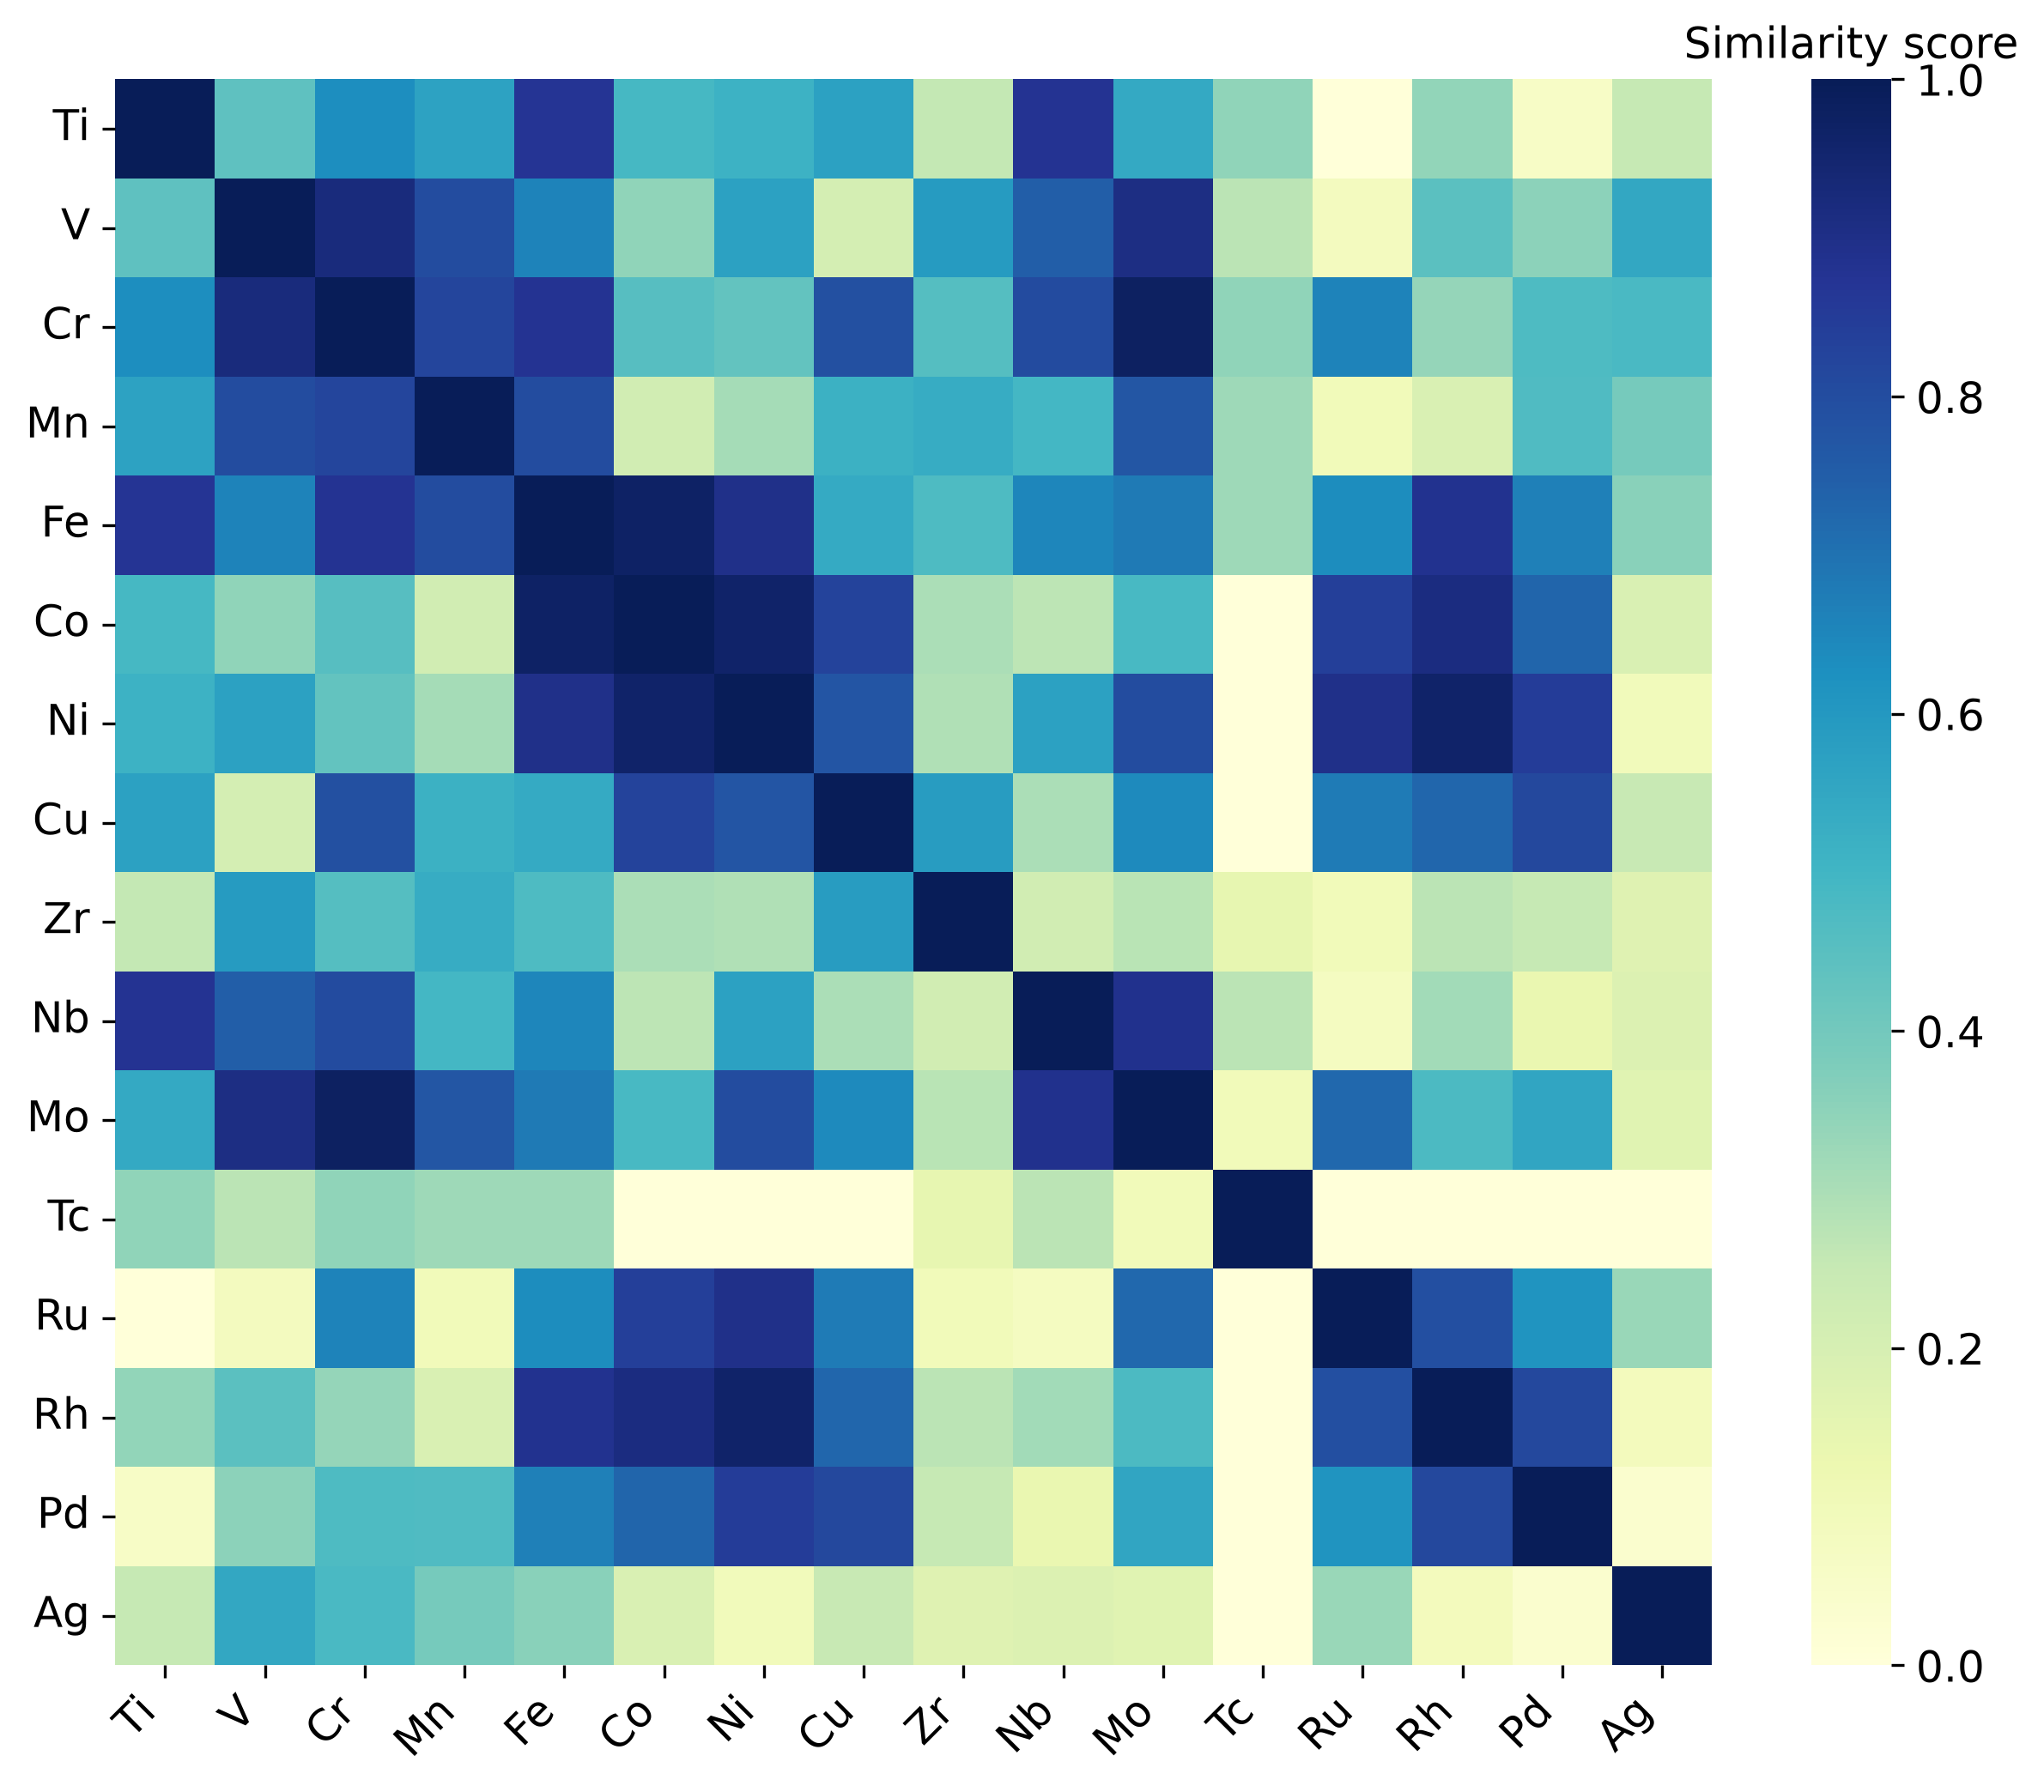

In [11]:
from ERS_misc import plot_similarity_matrix
plot_similarity_matrix(df_similarity, ELEMENTS)
import matplotlib.pyplot as plt
os.makedirs("image_executed", exist_ok=True)
plt.savefig("image_executed/elements_similarity.png")

## 第二段階

物質存在の信念割当関数の計算をします。


In [12]:
SCALE = .1 # 説明のs。パラメタです。


In [13]:
candidate = ["Fe", "Mn", "Co", "Ni"]


In [14]:
# alloy_k -> alloy_l = candidateへの元素置換の信念割当関数

from ERS_misc import extract_HEA_evidence
alloy_k = ["Co", "Cr", "Fe", "Ni"]
qstr = "combination=='{}'".format("".join(alloy_k))
label_alloy_k = df_data.query(qstr).iloc[0]["Label"]
evidence_1 = extract_HEA_evidence(frozenset(candidate), frozenset(alloy_k))
if evidence_1 is not None:
    combination_t, combination_v = evidence_1
    index_t = "|".join(sorted(combination_t))
    index_v = "|".join(sorted(combination_v))
    similar_score = df_similarity.loc[index_t, index_v]
    mass_function_1 = MassFunction(source=[({label_alloy_k},
                                    similar_score*SCALE)],
                                   coreset={"HEA", "not_HEA"})
    print(mass_function_1)


{frozenset({'HEA'}): np.float64(0.08230415670584258), frozenset({'not_HEA'}): 0, frozenset({'not_HEA', 'HEA'}): np.float64(0.9176958432941574)}


In [15]:
# alloy_k -> alloy_lへの元素置換の信念割当関数

alloy_k = ["Co", "Cr", "Mn"]
qstr = "combination=='{}'".format("".join(alloy_k))
label_alloy_k = df_data.query(qstr).iloc[0]["Label"]
evidence_2 = extract_HEA_evidence(frozenset(candidate), frozenset(alloy_k))
if evidence_2 is not None:
    combination_t, combination_v = evidence_2
    index_t = "|".join(sorted(combination_t))
    index_v = "|".join(sorted(combination_v))
    similar_score = df_similarity.loc[index_t, index_v]
    mass_function_2 = MassFunction(source=[({label_alloy_k},
                                    similar_score*SCALE)],
                                   coreset={"HEA", "not_HEA"})
    print(mass_function_2)


{frozenset({'not_HEA'}): np.float64(0.01799985239973432), frozenset({'HEA'}): 0, frozenset({'not_HEA', 'HEA'}): np.float64(0.9820001476002657)}


２つだけですが、この２つの信念構造の統合をします。


In [16]:
combined_mass_function = mass_function_1.combine(mass_function_2)
print(combined_mass_function)


{frozenset({'not_HEA'}): np.float64(0.016542897412157143), frozenset({'HEA'}): np.float64(0.08094260748486372), frozenset({'not_HEA', 'HEA'}): np.float64(0.9025144951029792)}
